# 09 - Demo: the intrusion detection system in action

**Goal:** show the trained model working on flows it has **never seen** (the test set), the way a bank's security
team would use it. Runs in seconds, no training.

| Section | What it shows |
|---|---|
| 1. One flow per class | True vs predicted label, confidence |
| 2. Analyse one flow | Its characteristics, probabilities, alert and suggested response |
| 3. Live traffic simulation | Flows arrive in batches, the system raises alerts |
| 4. Why this decision? (SHAP) | Which features pushed the model to its decision |
| 5. Interactive picker | Choose an attack type, analyse a random flow |

In [1]:
# Imports
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import joblib
from IPython.display import display
from google.colab import drive

# Mount Drive
drive.mount("/content/drive")

# Paths
BASE = Path("/content/drive/MyDrive/Projects/CSE-CIC-IDS2018")
DATA_DIR = BASE / "data" / "processed"
READY_DIR = BASE / "data" / "model_ready"
MODELS_DIR = BASE / "models"
RESULTS_DIR = BASE / "results"
SEED = 42
pd.set_option("display.max_columns", 100)

Mounted at /content/drive


## 0. Load the test data and the best model
The demo uses the best **tree model** (Random Forest, XGBoost, LightGBM...): they work on raw values and can be
explained with SHAP.

In [2]:
X_test = pd.read_parquet(READY_DIR / "X_test.parquet")
y_test = np.load(READY_DIR / "y_test.npy")
encoder = joblib.load(READY_DIR / "label_encoder.joblib")
class_names = list(encoder.classes_)

results = pd.DataFrame([json.load(open(f)) for f in RESULTS_DIR.glob("*_metrics.json")]).set_index("model")
candidates = ["LightGBM_tuned", "LightGBM", "XGBoost", "RandomForest", "DecisionTree"]
available = [m for m in candidates if m in results.index and (MODELS_DIR / f"{m}.joblib").exists()]

DEMO_MODEL = max(available, key=lambda m: results.loc[m, "macro_f1"])     # or write a name by hand
model = joblib.load(MODELS_DIR / f"{DEMO_MODEL}.joblib")

print("Demo model:", DEMO_MODEL)
print(results.loc[DEMO_MODEL, ["macro_f1", "accuracy", "detection_rate", "false_alarm_rate"]].round(4).to_string())
print(f"Test set: {len(X_test):,} unseen flows")

Demo model: RandomForest
macro_f1            0.8910
accuracy            0.8966
detection_rate      0.9798
false_alarm_rate    0.1701
Test set: 593,221 unseen flows


### Attack families and suggested responses

In [3]:
def family(label):
    if label == "Benign":
        return "Benign"
    if "DDOS" in label.upper():
        return "DDoS"
    if "DoS" in label:
        return "DoS"
    if "Brute" in label:
        return "Brute force"
    if label == "Web-Attack":
        return "Web attack"
    if label == "Bot":
        return "Botnet"
    if label == "Infilteration":
        return "Infiltration"
    return "Other"

RESPONSE = {
    "Benign": "No action.",
    "DoS": "Rate-limit the source, protect the web server (timeouts, connection limits).",
    "DDoS": "Activate upstream DDoS filtering, rate-limit at the edge router.",
    "Brute force": "Block the source IP, lock the targeted accounts, enforce MFA.",
    "Web attack": "Block the request at the web firewall, check the application logs.",
    "Botnet": "Isolate the infected machine (quarantine VLAN), block its remote control traffic.",
    "Infiltration": "Isolate the machine immediately and start incident response.",
    "Other": "Investigate.",
}

## 1. One flow per class
One random test flow from each class, predicted by the model.

In [4]:
rng = np.random.default_rng(7)          # change the seed to get other flows
rows = [rng.choice(np.flatnonzero(y_test == k)) for k in range(len(class_names))]

proba = model.predict_proba(X_test.iloc[rows])
pred = proba.argmax(axis=1)

pd.DataFrame({
    "true label": [class_names[y_test[i]] for i in rows],
    "predicted": [class_names[p] for p in pred],
    "confidence": proba.max(axis=1).round(3),
    "correct": np.where(pred == y_test[rows], "✅", "❌"),
}, index=rows).rename_axis("test row")

,true label,predicted,confidence,correct
test row,,,,
560268,Benign,Benign,0.929,✅
370527,Bot,Bot,1.000,✅
404700,DDOS attack-HOIC,DDOS attack-HOIC,1.000,✅
527561,DDOS attack-LOIC-UDP,DDOS attack-LOIC-UDP,1.000,✅
344781,DDoS attacks-LOIC-HTTP,DDoS attacks-LOIC-HTTP,1.000,✅
460843,DoS attacks-GoldenEye,DoS attacks-GoldenEye,1.000,✅
495659,DoS attacks-Hulk,DoS attacks-Hulk,1.000,✅
134753,DoS attacks-Slowloris,DoS attacks-Slowloris,1.000,✅
32138,Infilteration,Infilteration,0.920,✅


## 2. Analyse one flow
What a security analyst would see: the main characteristics of the connection, the model's top predictions,
the verdict and the suggested response.

Flow #370527


,Dst Port,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,Flow Byts/s,Flow Pkts/s
370527,8080.0,6.0,13602.0,3.0,4.0,33450.964844,514.630188


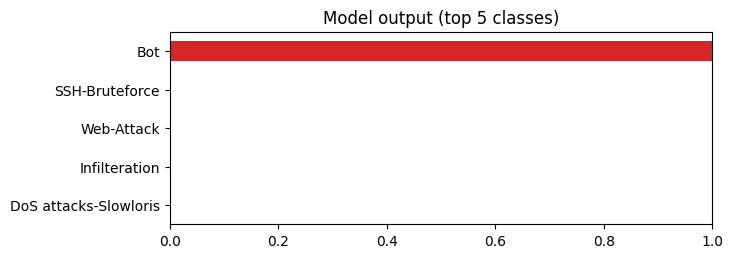

🚨 ALERT: Bot [Botnet] (confidence 100.0%)
True label: Bot → correct
Suggested response: Isolate the infected machine (quarantine VLAN), block its remote control traffic.


In [5]:
SHOW = ["Dst Port", "Protocol", "Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts", "Flow Byts/s", "Flow Pkts/s"]

def analyze_flow(i):
    x = X_test.iloc[[i]]
    p = model.predict_proba(x)[0]
    k = p.argmax()
    true, predicted = class_names[y_test[i]], class_names[k]

    print(f"Flow #{i}")
    display(x[[c for c in SHOW if c in x.columns]])

    top = pd.Series(p, index=class_names).sort_values().tail(5)
    colors = ["tab:green" if c == "Benign" else "tab:red" for c in top.index]
    top.plot(kind="barh", color=colors, figsize=(7, 2.5), xlim=(0, 1), title="Model output (top 5 classes)")
    plt.show()

    if predicted == "Benign":
        print(f"✅ NORMAL TRAFFIC (confidence {p[k]:.1%})")
    else:
        print(f"🚨 ALERT: {predicted} [{family(predicted)}] (confidence {p[k]:.1%})")
    print("True label:", true, "→", "correct" if true == predicted else "WRONG")
    print("Suggested response:", RESPONSE[family(predicted)])

attack_rows = [i for i in rows if class_names[y_test[i]] != "Benign"]
analyze_flow(attack_rows[0])

Flow #560268


,Dst Port,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,Flow Byts/s,Flow Pkts/s
560268,18038.0,6.0,86705352.0,2.0,0.0,0.0,0.023067


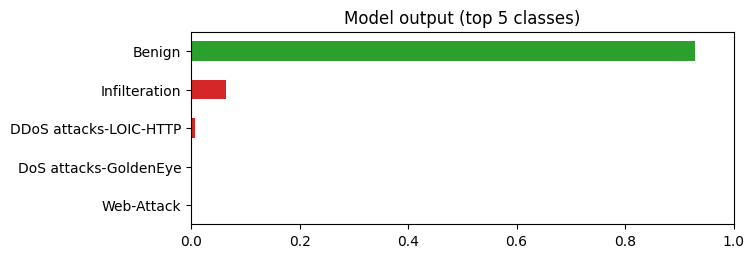

✅ NORMAL TRAFFIC (confidence 92.9%)
True label: Benign → correct
Suggested response: No action.


In [6]:
analyze_flow(rows[class_names.index("Benign")])

## 3. Live traffic simulation
Random test flows arrive in batches. The model classifies each batch and prints the alerts, like a monitoring console.

In [7]:
N_BATCHES = 10
BATCH_SIZE = 100
DELAY = 0.4              # seconds between batches

stream_rng = np.random.default_rng(2026)
log = []
for b in range(1, N_BATCHES + 1):
    batch_rows = stream_rng.choice(len(X_test), BATCH_SIZE, replace=False)
    batch_pred = model.predict_proba(X_test.iloc[batch_rows]).argmax(axis=1)

    alerts = pd.Series([class_names[p] for p in batch_pred if class_names[p] != "Benign"])
    top3 = ", ".join(f"{name} ×{n}" for name, n in alerts.value_counts().head(3).items())
    print(f"[{time.strftime('%H:%M:%S')}] batch {b:2d} | {BATCH_SIZE} flows | {len(alerts):3d} alerts | {top3}")

    log += [{"true": y_test[r], "pred": p} for r, p in zip(batch_rows, batch_pred)]
    time.sleep(DELAY)

log = pd.DataFrame(log)

[13:11:14] batch  1 | 100 flows |  49 alerts | DDoS attacks-LOIC-HTTP ×19, Infilteration ×16, DDOS attack-HOIC ×5
[13:11:15] batch  2 | 100 flows |  58 alerts | DDoS attacks-LOIC-HTTP ×26, DDOS attack-HOIC ×11, Infilteration ×10
[13:11:15] batch  3 | 100 flows |  52 alerts | Infilteration ×17, DDoS attacks-LOIC-HTTP ×17, DDOS attack-HOIC ×6
[13:11:16] batch  4 | 100 flows |  44 alerts | DDoS attacks-LOIC-HTTP ×13, Infilteration ×11, DDOS attack-HOIC ×11
[13:11:16] batch  5 | 100 flows |  54 alerts | DDoS attacks-LOIC-HTTP ×20, Infilteration ×16, DDOS attack-HOIC ×8
[13:11:16] batch  6 | 100 flows |  60 alerts | DDoS attacks-LOIC-HTTP ×20, Infilteration ×15, DDOS attack-HOIC ×7
[13:11:17] batch  7 | 100 flows |  49 alerts | DDoS attacks-LOIC-HTTP ×16, Infilteration ×10, DDOS attack-HOIC ×10
[13:11:17] batch  8 | 100 flows |  60 alerts | DDoS attacks-LOIC-HTTP ×19, Infilteration ×11, Bot ×11
[13:11:18] batch  9 | 100 flows |  49 alerts | DDoS attacks-LOIC-HTTP ×14, Infilteration ×14, Bot

In [8]:
BENIGN = class_names.index("Benign")
is_attack, pred_attack = log["true"] != BENIGN, log["pred"] != BENIGN

print(f"Flows analysed : {len(log):,}")
print(f"Real attacks   : {is_attack.sum():,}")
print(f"  detected     : {(is_attack & pred_attack).sum():,}")
print(f"  missed       : {(is_attack & ~pred_attack).sum():,}")
print(f"False alarms   : {(~is_attack & pred_attack).sum():,}")

Flows analysed : 1,000
Real attacks   : 433
  detected     : 429
  missed       : 4
False alarms   : 97


## 4. Why this decision? (SHAP)
Each bar shows how much a feature pushed the prediction **toward** (red) or **away from** (blue) the predicted class.
For XGBoost / LightGBM the values are in log-odds (raw score before the softmax), not probabilities.

In [9]:
!pip install -q shap

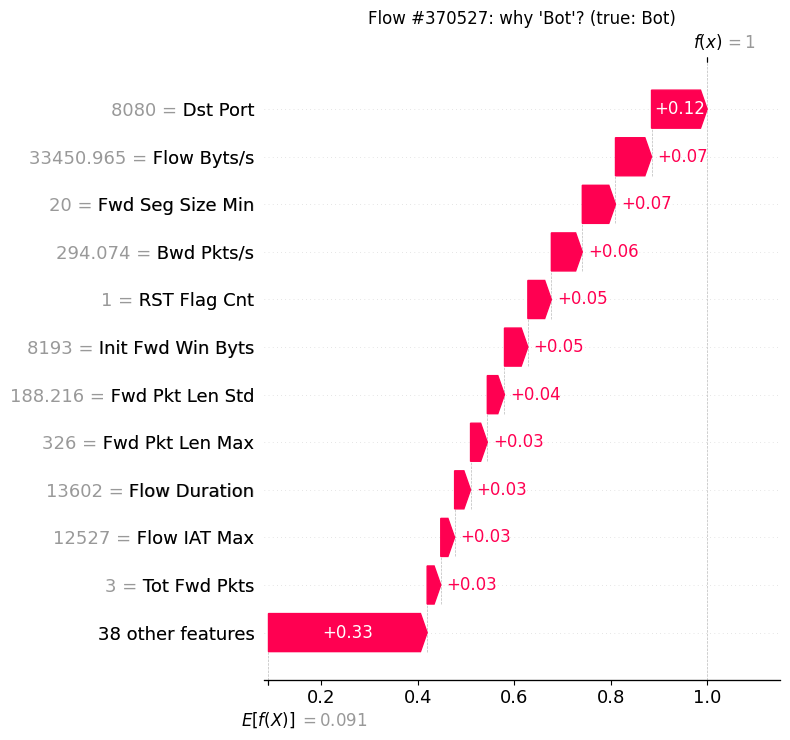

In [10]:
import shap

explainer = shap.TreeExplainer(model)

def explain_flow(i):
    x = X_test.iloc[[i]]
    k = model.predict_proba(x)[0].argmax()

    sv = explainer.shap_values(x)
    if isinstance(sv, list):                         # older SHAP versions
        sv = np.stack(sv, axis=-1)
    base = np.atleast_1d(explainer.expected_value)

    explanation = shap.Explanation(values=sv[0, :, k], base_values=base[k] if len(base) > 1 else base[0],
                                   data=x.iloc[0].to_numpy(), feature_names=list(X_test.columns))
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(f"Flow #{i}: why '{class_names[k]}'? (true: {class_names[y_test[i]]})")
    plt.tight_layout()
    plt.show()

explain_flow(attack_rows[0])

## 5. Interactive picker
Choose a class and click the button: a random unseen flow of that class is analysed and explained.

In [11]:
import ipywidgets as widgets

dropdown = widgets.Dropdown(options=class_names, description="Class:")
button = widgets.Button(description="Analyse a random flow", button_style="danger")
output = widgets.Output()

def on_click(_):
    with output:
        output.clear_output(wait=True)
        k = class_names.index(dropdown.value)
        i = int(np.random.choice(np.flatnonzero(y_test == k)))
        analyze_flow(i)
        explain_flow(i)

button.on_click(on_click)
display(widgets.HBox([dropdown, button]), output)

Output()

## Talking points for the soutenance
- The model only uses **flow statistics** (no IP addresses, no packet content), so it also works on encrypted traffic.
- Predictions take milliseconds per batch, so it could run in real time behind the bank's edge router.
- **Missed attacks vs false alarms:** missing an infiltration is worse than a false alarm, but too many false alarms
  tire the analysts. This trade-off drives the choice of metrics.
- **Link with Partie 1:** the targeted ports (SSH, HTTP...) are services of the Packet Tracer network; the suggested
  responses map to ACLs, VLAN isolation and rate limiting there.